# Mini-modèle ALM fonds euros : V3 Solvabilité II simplifié

La V3 construit un bilan Solvabilité II simplifié du fonds et calcule un SCR par chocs, à la manière de la formule standard. **Ce n'est pas un calcul réglementaire complet** : plusieurs modules de risque, le risque opérationnel et les impôts différés sont absents (voir la fin du notebook).

**Principe.** On applique chaque choc à l'ouverture, on relance toute la projection stochastique de la V2 sur les mêmes tirages, puis on mesure la perte de fonds propres économiques (VM de l'actif - BE).

| Choc | Règle appliquée | Référence |
| --- | --- | --- |
| Taux | chocs relatifs par maturité ; hausse d'au moins 1 point ; pas de baisse d'un taux négatif | Règlement délégué (UE) 2015/35, art. 166 et 167, version applicable jusqu'au 29/01/2027 |
| Actions | -39 % (type 1), ajustement symétrique pris nul | Art. 169 et 172 |
| Rachats à la hausse | taux de rachat × 1,5, plafonné à 100 % | Art. 142 |
| Rachats à la baisse | taux de rachat × 0,5, sans baisser de plus de 20 points | Art. 142 |
| Rachat massif | 40 % de la PM rachetée immédiatement | Art. 142 |

**Perte nette, perte brute.**
- **Perte nette** : sous choc, le modèle ajuste le taux servi et la PPB. La perte inclut donc l'absorption par les participations futures.
- **Perte brute** : perte nette + (FDB de base - FDB après choc). C'est la perte quand le choc ne change pas la valeur des FDB (règlement délégué (UE) 2015/35, art. 83(1)(c)), calculée selon la méthode de l'orientation 2 des orientations EIOPA sur la capacité d'absorption des pertes (EIOPA-BoS-14/177). Limite : les prestations garanties sous choc reprennent les sorties du calcul net.

Le calcul prend environ deux minutes : sept projections de 1 000 scénarios sur 60 ans.

In [1]:
import os, subprocess, sys
if not os.path.exists("src"):
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    else:
        if not os.path.exists("mini-alm-fonds-euros"):
            subprocess.run(["git", "clone", "https://github.com/TorjmenYou/mini-alm-fonds-euros.git"], check=True)
        os.chdir("mini-alm-fonds-euros")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.hypotheses import charger_hypotheses
h = charger_hypotheses()

BLEU, ORANGE, VERT, JAUNE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
ENCRE, ENCRE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "axes.edgecolor": GRILLE,
    "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
pd.set_option("display.precision", 4)

def titre(ax, texte):
    ax.set_title(texte, loc="left", color=ENCRE, fontsize=11)

In [2]:
from src.solvabilite import calculer_scr
res = calculer_scr(h)

taux = pd.DataFrame({
    "Base": [res["courbes"]["base"].taux_maturite(m) * 100 for m in (1, 5, 10, 20, 30, 60)],
    "Hausse": [res["courbes"]["hausse"].taux_maturite(m) * 100 for m in (1, 5, 10, 20, 30, 60)],
    "Baisse": [res["courbes"]["baisse"].taux_maturite(m) * 100 for m in (1, 5, 10, 20, 30, 60)],
}, index=pd.Index([1, 5, 10, 20, 30, 60], name="Maturité (ans)"))
taux.round(2)

,Base,Hausse,Baisse
Maturité (ans),,,
1,3.0,5.10,0.75
5,3.0,4.65,1.62
10,3.0,4.26,2.07
20,3.0,4.00,2.13
30,3.0,4.00,2.17
60,3.0,4.00,2.28


Lecture : sur une courbe plate à 3 %, le choc relatif à la hausse est fort aux courtes maturités (+70 % à 1 an, soit 5,1 %), puis s'atténue. Au-delà de 20 ans, la hausse minimale d'un point s'applique, et le taux passe à 4 %. À la baisse, le taux à 10 ans passe à 2,07 % (-31 %).

In [3]:
noms = {"base": "Base", "taux_hausse": "Taux à la hausse", "taux_baisse": "Taux à la baisse", "actions": "Actions -39 %",
        "rachats_hausse": "Rachats x 1,5", "rachats_baisse": "Rachats x 0,5", "rachat_massif": "Rachat massif 40 %"}
lignes = []
for cle, nom in noms.items():
    s = res["runs"][cle]["synthese"]
    lignes.append({"Scénario": nom, "Actif (VM)": s["vm_actif_initial"], "BE": s["be"],
                   "Fonds propres économiques": res["fonds_propres_economiques"][cle], "FDB": res["fdb"][cle],
                   "Perte nette": res["pertes_nettes"].get(cle, 0.0), "IC nette (±)": res["ic_pertes_nettes"].get(cle, 0.0),
                   "Perte brute": res["pertes_brutes"].get(cle, 0.0), "IC brute (±)": res["ic_pertes_brutes"].get(cle, 0.0)})
chocs = pd.DataFrame(lignes).set_index("Scénario")
chocs.round(1)

,Actif (VM),BE,Fonds propres économiques,FDB,Perte nette,IC nette (±),Perte brute,IC brute (±)
Scénario,,,,,,,,
Base,1078.2,987.4,90.9,178.6,0.0,0.0,0.0,0.0
Taux à la hausse,1013.2,935.3,77.9,171.0,12.9,2.9,20.6,3.0
Taux à la baisse,1136.3,1045.4,90.9,168.6,-0.0,3.8,10.0,3.6
Actions -39 %,1031.4,967.0,64.4,138.3,26.4,0.6,66.7,0.9
"Rachats x 1,5",1078.2,997.4,80.8,147.3,10.1,1.4,41.4,1.6
"Rachats x 0,5",1078.2,962.1,116.1,241.8,-25.2,2.3,-88.5,2.6
Rachat massif 40 %,1078.2,1001.3,76.9,121.5,14.0,2.2,71.0,2.5


Lecture, choc par choc :
- **Taux à la hausse** : l'actif perd environ 65 (moins-values obligataires) et le BE baisse d'environ 52. Mais les rachats conjoncturels et un taux servi qui doit suivre le marché limitent la baisse du passif : la perte nette est d'environ 13.
- **Taux à la baisse** : l'actif et le BE montent tous deux d'environ 58. La perte nette est quasi nulle, c'est donc la hausse qui dimensionne le risque de taux.
- **Actions -39 %** : l'actif perd environ 47 et le BE baisse d'environ 20. Les assurés absorbent un peu plus de 40 % du choc à travers des participations futures plus faibles (les FDB passent d'environ 179 à environ 138).
- **Rachats** : un rachat fait sortir la PM à sa valeur comptable, alors qu'un euro de PM vaut moins d'un euro en BE (l'assureur y garde des marges futures). Plus de rachats, c'est donc une perte de marges futures. Le rachat massif est le choc de rachat le plus coûteux.
- **FDB** : elles restent positives dans tous les scénarios choqués.
- **Précision** : base et chocs partagent les mêmes tirages, donc les intervalles à 95 % des pertes sont calculés sur les écarts scénario par scénario. Ils sont bien plus étroits que celui du BE (±6).

In [4]:
net, brut = res["scr_net"], res["scr_brut"]
pd.DataFrame({"Net (après absorption)": net, "Brut (FDB inchangées)": brut}).rename(index={
    "taux": "Taux", "actions": "Actions", "marche": "SCR marché", "rachat": "Rachat", "bscr": "BSCR"}).round(1)

,Net (après absorption),Brut (FDB inchangées)
Taux,12.9,20.6
Actions,26.4,66.7
SCR marché,29.4,69.8
Rachat,14.0,71.0
BSCR,35.6,111.4


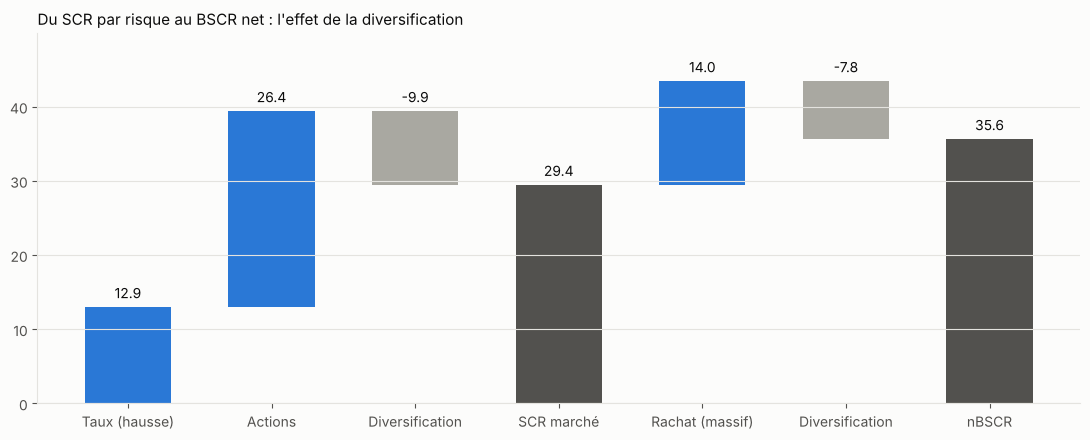

In [5]:
somme_marche = net["taux"] + net["actions"]
etapes = [
    ("Taux (hausse)", net["taux"], "module"),
    ("Actions", net["actions"], "module"),
    ("Diversification", net["marche"] - somme_marche, "diversification"),
    ("SCR marché", net["marche"], "total"),
    ("Rachat (massif)", net["rachat"], "module"),
    ("Diversification", net["bscr"] - net["marche"] - net["rachat"], "diversification"),
    ("nBSCR", net["bscr"], "total"),
]
couleurs = {"module": BLEU, "diversification": "#a9a8a1", "total": ENCRE_2}
fig, ax = plt.subplots(figsize=(11, 4.5))
niveau = 0.0
for i, (nom, valeur, genre) in enumerate(etapes):
    if genre == "total":
        bas, haut = 0.0, valeur
        niveau = valeur
    else:
        bas, haut = sorted((niveau, niveau + valeur))
        niveau += valeur
    ax.bar(i, haut - bas, bottom=bas, color=couleurs[genre], width=0.6)
    ax.text(i, haut + 0.8, f"{valeur:+.1f}" if genre == "diversification" else f"{valeur:.1f}",
            ha="center", va="bottom", color=ENCRE, fontsize=10)
ax.set_xticks(range(len(etapes)), [e[0] for e in etapes])
ax.set_ylim(0, (net["marche"] + net["rachat"]) * 1.15)
ax.grid(axis="x", visible=False)
titre(ax, "Du SCR par risque au BSCR net : l'effet de la diversification")
fig.tight_layout()
fig.savefig("figures/scr.png", dpi=150, bbox_inches="tight")
plt.show()

Lecture : les modules ne s'additionnent pas. Les corrélations de la formule standard réduisent le total :
- 0 entre taux et actions, car c'est la hausse des taux qui est retenue ;
- 0,25 entre risque de marché et risque de rachat.

La diversification retire environ 10 au SCR marché, puis environ 8 au total.

In [6]:
pd.Series({
    "BSCR brut": brut["bscr"],
    "nBSCR (net)": net["bscr"],
    "FDB de base": res["fdb"]["base"],
    "Ajustement (art. 206) = -max(min(BSCR - nBSCR, FDB), 0)": res["ajustement_tp"],
    "SCR simplifié = BSCR + ajustement": res["scr"],
    "Marge avant plafond = FDB - (BSCR - nBSCR)": res["controles"]["marge_avant_plafond_fdb"],
}).round(1).to_frame("Montant")

,Montant
BSCR brut,111.4
nBSCR (net),35.6
FDB de base,178.6
"Ajustement (art. 206) = -max(min(BSCR - nBSCR, FDB), 0)",-75.8
SCR simplifié = BSCR + ajustement,35.6
Marge avant plafond = FDB - (BSCR - nBSCR),102.8


Lecture :
- **L'absorption par les participations futures** (environ 76) reste bien inférieure aux FDB disponibles (environ 179) : le plafond de l'article 206 n'est pas atteint, et le SCR simplifié est égal au nBSCR.
- **Sensibilité au calcul brut** : quand le plafond n'est pas atteint, SCR = BSCR - (BSCR - nBSCR) = nBSCR, et le SCR ne dépend pas du calcul brut. Le calcul brut sert seulement à vérifier le plafond, ici avec une marge d'environ 103.
- **Ce que ce calcul n'est pas** : un calcul brut direct, à flux de FDB figés, n'a pas été réalisé, et l'écart entre les deux méthodes n'est pas mesuré. Les tests vérifient la cohérence interne (formules, choix des scénarios, cas sans FDB où brut = net) : ce n'est pas une validation indépendante.

In [7]:
for nom, b in res["bilans"].items():
    print(f"{nom} : {b['libelle']}")
bilan = pd.DataFrame({nom: {k: v for k, v in b.items() if k != "libelle"} for nom, b in res["bilans"].items()}).rename(index={
    "actif": "Actif (VM)", "be": "Best Estimate", "dont_fdb": "dont FDB", "marge_risque": "Marge de risque",
    "fonds_propres": "Fonds propres", "scr": "SCR simplifié", "fonds_propres_sur_scr": "Fonds propres / SCR simplifié"})
bilan.columns = ["Règles de 2026", "Sensibilité : marge de risque aux paramètres 2027"]
bilan.round(2)

regles_2026 : Règles en vigueur en 2026 : marge de risque au coût du capital de 6 % (règlement délégué (UE) 2015/35, art. 37 et 39)
sensibilite_mr_2027 : Sensibilité : seuls les paramètres de marge de risque du règlement délégué (UE) 2026/269 (coût du capital de 4,75 %, facteur max(0,96^t ; 50 %)) ; chocs, courbe et SCR inchangés (règles de 2026)


,Règles de 2026,Sensibilité : marge de risque aux paramètres 2027
Actif (VM),1078.20,1078.20
Best Estimate,987.35,987.35
dont FDB,178.60,178.60
Marge de risque,8.51,5.13
Fonds propres,82.34,85.72
SCR simplifié,35.59,35.59
Fonds propres / SCR simplifié,2.31,2.41


Lecture :
- **Marge de risque** : environ 8,5 au coût du capital de 6 % en vigueur en 2026. Le SCR non couvrable retenu est le SCR de rachat après absorption, projeté au rythme d'écoulement de la PM.
- **Sensibilité 2027** : environ 5,1 si l'on remplace seulement les paramètres de marge de risque par ceux du règlement délégué (UE) 2026/269, applicables à partir du 30 janvier 2027 (coût du capital de 4,75 % et facteur max(0,96^t ; 50 %) sur les SCR futurs). **Ce n'est pas un calcul selon le régime révisé** : les chocs (dont la nouvelle méthode de choc de taux), la courbe et le SCR restent ceux des règles de 2026. Seule la marge de risque change entre les deux colonnes.
- **Fonds propres / SCR simplifié** : environ 2,3 aux règles de 2026, et environ 2,4 dans la sensibilité. **Ce n'est pas un ratio de solvabilité réglementaire** : il manque plusieurs modules de risque, le risque opérationnel et l'ajustement pour impôts différés. Il sert à comparer des versions du modèle ou des stratégies entre elles.
- **Le sous-module le plus lourd est le risque actions** (environ 26), devant le rachat massif (environ 14) et la hausse des taux (environ 13). Au niveau des modules, le risque de marché (environ 29) pèse environ deux fois plus que le risque de rachat.

## Limites de la V3
- **Courbe** : plate à 3 %, sans la courbe EIOPA ni son extrapolation réglementaire.
- **Régime révisé (règlement délégué (UE) 2026/269)** : non implémenté. Seuls les paramètres de marge de risque font l'objet d'une sensibilité ; la nouvelle méthode de choc de taux et les autres changements ne sont pas modélisés.
- **Modules absents** : spread, immobilier, change, mortalité, frais, catastrophe, risque opérationnel ; pas d'ajustement pour impôts différés. L'ajustement symétrique actions est pris nul.
- **Choc de rachat** : un seul model point, sans sélection des contrats concernés.
- **Perte brute** : déduite de la perte nette par la variation des FDB (orientation EIOPA 2), sans calcul brut direct à flux de FDB figés ; les sorties des prestations garanties sont celles du calcul net.
- **PPB** : entièrement dans le BE, sans reconnaissance en fonds excédentaires (arrêté du 24 décembre 2019).